# Day 5 - Data-size experiments

The reusable experiment is in `src/day5_training_size.py`. It uses the fixed validation partition and nested 25%, 50%, and 100% training prefixes.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from src.day5_training_size import run_training_size_experiment
train = pd.read_parquet(ROOT / 'data/processed/train.parquet')
validation = pd.read_parquet(ROOT / 'data/processed/validation.parquet')
summary = run_training_size_experiment(train, validation)
summary.to_csv(ROOT / 'results/tables/day5_training_size.csv', index=False)
display(summary)

,fraction,train_rows,features,accuracy,macro_f1,weighted_f1,seconds
0,0.25,34677,300000,0.754180,0.712905,0.748823,76.310692
1,0.50,69355,300000,0.771936,0.733592,0.767656,114.618701
2,1.00,138711,300000,0.786751,0.751617,0.783779,245.086164


Saved Day 5 table and figure.


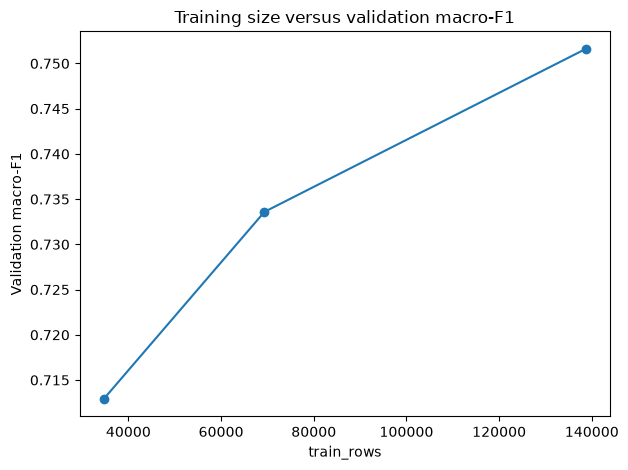

In [2]:
import matplotlib.pyplot as plt
ax = summary.plot(x='train_rows', y='macro_f1', marker='o', legend=False)
ax.set_ylabel('Validation macro-F1')
ax.set_title('Training size versus validation macro-F1')
plt.tight_layout()
plt.savefig(ROOT / 'results/figures/day5_training_size_macro_f1.png', dpi=150)
print('Saved Day 5 table and figure.')